<h1  style="color:#000000; text-align:center; font-weight:bold;">DATASCI 530 Assignment 5</h1>
<h1  style="color:#000000; text-align:center; font-weight:bold;">Predicting Class Labels for Iris Flowers</h1>
<p  style="color:#000000; text-align:center; font-size:18px;">Maxine Hakimi-Bulson</p>

<h2 style="color:#000000;">Predicting the Class Label</h2>

The Iris dataset contains measurements of three iris flower species. Each flower is described by four features: sepal length, sepal width, petal length, and petal width. In this analysis, I compare classification methods to see how well they use these measurements to correctly predict a flower’s species.

<h2 style="color:#000000;">Summary of Findings</h2>

Here are the main findings:

- The Iris dataset contains 150 flowers from three species, all equally represented.

- All four classification methods performed well, with Naive Bayes having the highest average accuracy and macro F1. The tuned SVM had the highest ROC AUC.

- The models typically didn't misclassify the same flowers: the tuned SVM and neural network had the least overlap in errors, and the random forest and Naive Bayes had the most similar errors.

- Naive Bayes is recommended for this dataset based on its accuracy and macro F1.

<h2 style="color:#000000;">Loading Libraries and Data</h2>

First we will load the necessary libraries and data to complete our analyses.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf

from sklearn.model_selection import (
    StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import make_pipeline

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

from tensorflow import keras
from keras.layers import Dense
from IPython.display import display, HTML

In [27]:
# Load the Iris dataset and assign column names since
# they currently don't have column names
iris = pd.read_csv(
    "data/iris/iris.data",
    header=None,
    names=[
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width",
        "class"
    ]
)

<h2 style="color:#000000;">Inquiry & Analysis</h2>

<h3 style="color:#000000;"> Description of Dataset</h3>

All of the descriptive statistics of the dataset can be found using Data Wrangler. I made a table showing the number of observations and proportions of each class.

In [28]:
# Count observations and calculate the proportion in each class
table_classes = pd.DataFrame({
    "Number of Observations": iris["class"].value_counts()
})

table_classes["Proportion"] = (
    table_classes["Number of Observations"] / len(iris)
)

# Turn the class names into a regular column
table_classes = table_classes.reset_index()
table_classes = table_classes.rename(columns={"class": "Class"})

# Display the formatted table
display(
    table_classes.style
    .format({"Proportion": "{:.1%}"})
    .hide(axis="index")
    .set_caption("Distribution of Iris Classes")
)

Class,Number of Observations,Proportion
Iris-setosa,50,33.3%
Iris-versicolor,50,33.3%
Iris-virginica,50,33.3%


There are 150 rows, four continuous features (sepal length/width, petal length/width), and three categorical labels for iris classification: "Iris-setosa," "Iris-versicolor," and "Iris-virginica." Each class has 50 observations, representing one third of the total observations in this dataset.

<h3 style="color:#000000;"> Run a comparison of different machine learning methods </h3>

- Evaluate the predictive performance using cross-validation. Consider more than one evaluation metric.
- Use the default tuning parameters for all methods except one (you choose). For this method, define a grid of tuning parameters and select the best-performing ones.

I used the four flower measurements to predict iris species and compared a support vector machine (SVM), random forest, neural network, and Naive Bayes classifier. I evaluated each method using the same five stratified cross-validation folds and calculated average accuracy, macro F1, and one-versus-rest ROC AUC across the validation folds.

I used the default tuning parameters for the random forest and Naive Bayes models. For the neural network, I followed the Lecture 16 example by using a 16-unit hidden layer and training for 100 epochs, with an output layer adapted for the three iris species. For the SVM, I used a grid search with three-fold cross-validation to select C and gamma based on accuracy within each training fold. I standardized the predictors for the SVM and neural network using the training data for each fold. I then ran the SVM grid search on the full dataset to select a final set of parameters, which were C = 10 and gamma = 0.1.

In [31]:
# Define the predictors and outcome
X = iris.drop(columns="class")
y = iris["class"]

# Convert species names to numbers for the neural network
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Use the same five stratified folds for all four models
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

# Define the SVM and scale its predictors
svm = make_pipeline(
    StandardScaler(),
    SVC(probability=True, random_state=0)
)

# Define the SVM tuning grid
param_grid = {
    "svc__C": [0.01, 0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1, 1]
}

# Tune the SVM within each training fold
svm_tuned = GridSearchCV(
    svm,
    param_grid,
    scoring="accuracy",
    cv=3
)

# Define the other scikit-learn models
random_forest = RandomForestClassifier(random_state=0)
naive_bayes = GaussianNB()

# Store the scikit-learn methods
models = {
    "SVM (tuned)": svm_tuned,
    "Random Forest": random_forest,
    "Naive Bayes": naive_bayes
}

# Store fold results and validation predictions
model_results = []
model_names = ["SVM (tuned)", "Random Forest", "Neural Network", "Naive Bayes"]

model_predictions = {
    name: np.empty(len(y), dtype=object)
    for name in model_names
}

# Repeat the analysis for each training/validation split
for fold, (train_index, test_index) in enumerate(
    cv.split(X, y), start=1
):
    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    # Fit and evaluate the SVM, random forest, and Naive Bayes
    for model_name, model in models.items():

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)
        probabilities = model.predict_proba(X_test)

        model_predictions[model_name][test_index] = predictions

        model_results.append({
            "Model": model_name,
            "Fold": fold,
            "Accuracy": accuracy_score(y_test, predictions),
            "Macro F1": f1_score(
                y_test, predictions, average="macro"
            ),
            "ROC AUC": roc_auc_score(
                y_test,
                probabilities,
                labels=model.classes_,
                multi_class="ovr",
                average="macro"
            )
        })

    # Standardize using only this fold's training data
    scaler_train = StandardScaler().fit(X_train)

    X_train_scale = scaler_train.transform(X_train).astype(np.float32)
    X_test_scale = scaler_train.transform(X_test).astype(np.float32)

    # Use numeric labels for the neural network
    y_train_nn = y_encoded[train_index]
    y_test_nn = y_encoded[test_index]

    # Set the seed before building each network
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(0)

    # Build the network following Lecture 16
    neural_network = keras.models.Sequential()
    neural_network.add(keras.Input(shape=(X_train.shape[1],)))
    neural_network.add(Dense(units=16, activation="relu"))

    # Three output units: one for each iris species
    neural_network.add(Dense(units=3, activation="softmax"))

    # Compile and train the model
    adam = keras.optimizers.Adam(learning_rate=0.001)

    neural_network.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=adam,
        metrics=["accuracy"]
    )

    neural_network.fit(
        X_train_scale,
        y_train_nn,
        epochs=100,
        verbose=0
    )

    # Predict probabilities and select the most likely species
    probabilities_nn = neural_network.predict(
        X_test_scale, verbose=0
    )

    predicted_numbers = np.argmax(probabilities_nn, axis=1)
    predictions_nn = label_encoder.inverse_transform(predicted_numbers)

    model_predictions["Neural Network"][test_index] = predictions_nn

    # Calculate the same metrics for the neural network
    model_results.append({
        "Model": "Neural Network",
        "Fold": fold,
        "Accuracy": accuracy_score(y_test, predictions_nn),
        "Macro F1": f1_score(
            y_test, predictions_nn, average="macro"
        ),
        "ROC AUC": roc_auc_score(
            y_test_nn,
            probabilities_nn,
            multi_class="ovr",
            average="macro"
        )
    })

# Calculate average performance across the five folds
table_models = (
    pd.DataFrame(model_results)
    .groupby("Model")[["Accuracy", "Macro F1", "ROC AUC"]]
    .mean()
    .sort_values("Accuracy", ascending=False)
    .reset_index()
)

# Format the model comparison table
models_html = (
    table_models.style
    .format({
        "Accuracy": "{:.1%}",
        "Macro F1": "{:.3f}",
        "ROC AUC": "{:.3f}"
    })
    .hide(axis="index")
    .set_caption("Five-Fold Cross-Validation Results by Model")
    .to_html()
)

# Select final SVM parameters using the full dataset
final_svm_grid = GridSearchCV(
    svm,
    param_grid,
    scoring="accuracy",
    cv=3
)

final_svm_grid.fit(X, y)

table_svm_parameters = pd.DataFrame({
    "Parameter": ["C", "Gamma"],
    "Selected Value": [
        str(final_svm_grid.best_params_["svc__C"]),
        str(final_svm_grid.best_params_["svc__gamma"])
    ]
})

svm_html = (
    table_svm_parameters.style
    .hide(axis="index")
    .set_caption("Final SVM Parameters Selected Using All Observations")
    .to_html()
)

# Display the tables side by side
from IPython.display import display, HTML

display(HTML(
    '<div style="display:flex; gap:30px; align-items:flex-start;">'
    '<div>' + models_html + '</div>'
    '<div>' + svm_html + '</div>'
    '</div>'
))

Naive Bayes had the highest average accuracy (96.0%) and macro F1 score (0.960), followed closely by the tuned SVM (95.3% and 0.953). The tuned SVM had the highest ROC AUC (0.998), although all four models had high ROC AUC scores. The neural network had the lowest accuracy (91.3%) and macro F1 score (0.912) in this comparison. Based on accuracy and macro F1, I would recommend Naive Bayes for this dataset, while recognizing that its advantage over the SVM was small and the dataset contained only 150 flowers.

<h2 style="color:#000000;">New Insights</h2>

<h3 style="color:#000000;"> Do the classification methods tend to make mistakes on the same iris flowers? </h3>

I used cross-validation to obtain a prediction for each flower from each model, with each prediction made while that flower was in a validation fold. For each pair of models, I compared the flowers they classified incorrectly using Jaccard similarity: the number misclassified by both models divided by the number misclassified by at least one. I displayed the similarities in a heatmap, where values closer to 1 indicate greater overlap in errors.

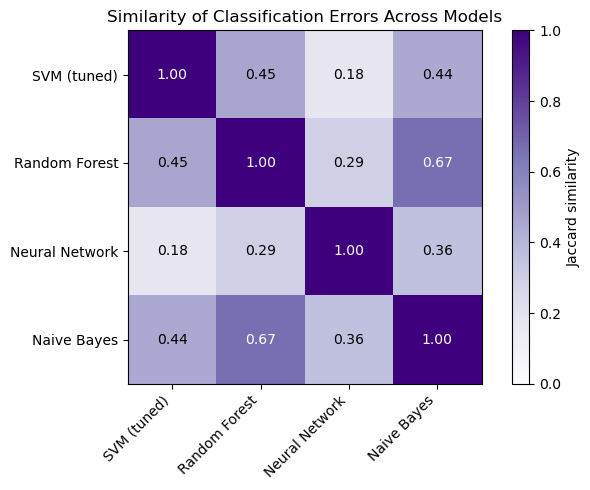

In [32]:
# Identify which flowers each model classified incorrectly
model_errors = {}

for model_name, predictions in model_predictions.items():
    model_errors[model_name] = predictions != y.to_numpy()

# Create an empty table for pairwise Jaccard similarities
model_names = list(model_predictions.keys())

jaccard_table = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

# Compare the sets of misclassified flowers for each pair of models
for model_1 in model_names:
    for model_2 in model_names:
        errors_1 = model_errors[model_1]
        errors_2 = model_errors[model_2]

        # Flowers both models got wrong
        shared_errors = (errors_1 & errors_2).sum()

        # Flowers at least one model got wrong
        either_error = (errors_1 | errors_2).sum()

        # Jaccard similarity is undefined if neither model made an error
        if either_error > 0:
            jaccard_table.loc[model_1, model_2] = (
                shared_errors / either_error
            )
        else:
            jaccard_table.loc[model_1, model_2] = np.nan

# Plot the similarity matrix
fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(
    jaccard_table,
    cmap="Purples",
    vmin=0,
    vmax=1
)

# Label the rows and columns
ax.set_xticks(range(len(model_names)))
ax.set_xticklabels(model_names, rotation=45, ha="right")
ax.set_yticks(range(len(model_names)))
ax.set_yticklabels(model_names)

# Add each similarity value to its cell
for row in range(len(model_names)):
    for col in range(len(model_names)):
        value = jaccard_table.iloc[row, col]

        if pd.notna(value):
            ax.text(
                col, row, f"{value:.2f}",
                ha="center",
                va="center",
                color="white" if value > 0.6 else "black"
            )

ax.set_title("Similarity of Classification Errors Across Models")
fig.colorbar(image, ax=ax, label="Jaccard similarity")
plt.tight_layout()
plt.show()

<h3 style="color:#000000;"> What do we learn from this new figure?  </h3>

The tuned SVM and neural network had the lowest similarity in their classification errors (0.18). This means that, among the flowers misclassified by at least one of these models, approximately 18% were misclassified by both. In contrast, the random forest and Naive Bayes had the greatest overlap in errors among the different model pairs, with a similarity of 0.67. These results show that the models did not always make mistakes on the same flowers. Because relatively few flowers were misclassified, the similarity scores may be sensitive to a small change in the number of errors.

<h2 style="color:#000000;">Final Recommendation</h2>

I recommend Naive Bayes for predicting iris species because it had the highest average cross-validation accuracy (96.0%) and macro F1 score (0.960) among the methods compared. The tuned SVM had a slightly higher ROC AUC, but its accuracy and macro F1 were slightly lower. The differences were small and the dataset contained only 150 flowers, so the recommendation is based on this particular comparison rather than evidence that Naive Bayes will always perform best.